# 02 - Regression: Predicting % Silica in the Concentrate

Goal: predict the % silica of the current hour from the plant sensors and the previous hour's lab result.

Methods: Multiple Linear Regression (normal equation and our own gradient descent),
Ridge and Lasso regularization, and a Random Forest regressor for comparison.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from src import data
from src.plot_style import setup, save, COLORS
setup()

In [2]:
hourly = data.load_hourly()
train, test = data.time_split(hourly)

X_train, y_train = train[data.FEATURES], train[data.TARGET]
X_test, y_test = test[data.FEATURES], test[data.TARGET]

scaler = StandardScaler().fit(X_train)          # fitted on training data only
Xs_train = scaler.transform(X_train)
Xs_test = scaler.transform(X_test)
print("Train:", Xs_train.shape, " Test:", Xs_test.shape)

Train: (2762, 23)  Test: (1185, 23)


In [3]:
def scores(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred)}

results = {}

## 1. Baseline: "same as last hour"
Before any ML, the simplest possible prediction is: silica this hour = silica last hour.
Any useful model has to beat this.

In [4]:
results["Baseline (last hour)"] = scores(y_test, X_test["silica_prev_hr"])
results["Baseline (last hour)"]

{'R2': 0.6076177554188391,
 'RMSE': np.float64(0.7105932991854919),
 'MAE': 0.4328354430379748}

## 2. Multiple Linear Regression with the normal equation
Model: y = b0 + b1 x1 + ... + b23 x23. The least-squares solution is

$$\beta = (X^T X)^{-1} X^T y$$

where X has a column of ones for the intercept. We compute it with numpy and check it against scikit-learn.

In [5]:
Xb_train = np.c_[np.ones(len(Xs_train)), Xs_train]      # add the column of ones
beta_ne = np.linalg.solve(Xb_train.T @ Xb_train, Xb_train.T @ y_train.values)

mlr = LinearRegression().fit(Xs_train, y_train)
print("Intercept  normal eq: %.4f   sklearn: %.4f" % (beta_ne[0], mlr.intercept_))
print("Max difference in coefficients:", np.abs(beta_ne[1:] - mlr.coef_).max())

Intercept  normal eq: 2.3075   sklearn: 2.3075
Max difference in coefficients: 4.6129766673175254e-14


Same answer, so our formula is correct.

## 3. Gradient descent (written from scratch)
Instead of inverting X^T X we can minimise the cost step by step.

Cost (mean squared error): $$J(\beta) = \frac{1}{2n}\sum_{i=1}^{n}(\hat y_i - y_i)^2$$

Gradient: $$\frac{\partial J}{\partial \beta} = \frac{1}{n} X^T(X\beta - y)$$

Update rule: $$\beta := \beta - \alpha \, \frac{\partial J}{\partial \beta}$$

Scaling the features first is important here, otherwise one learning rate does not suit all coefficients.

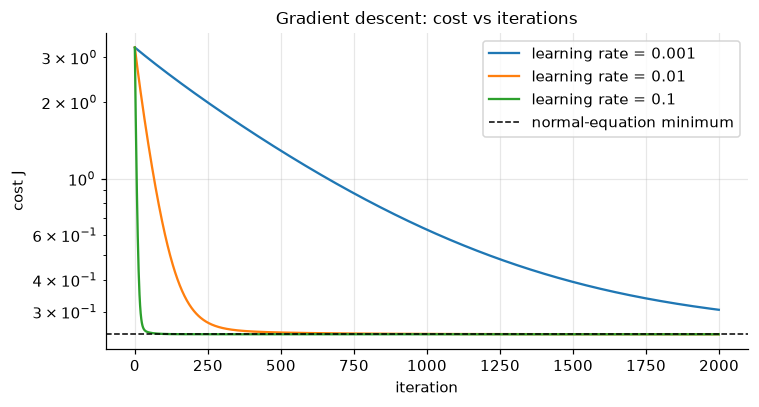

lr=0.001  final cost=0.30554   max |beta_GD - beta_NE| = 0.3120
lr=0.01   final cost=0.24485   max |beta_GD - beta_NE| = 0.0797
lr=0.1    final cost=0.24471   max |beta_GD - beta_NE| = 0.0031


In [6]:
def gradient_descent(X, y, lr=0.1, n_iter=2000):
    n = len(y)
    beta = np.zeros(X.shape[1])
    cost_history = []
    for _ in range(n_iter):
        error = X @ beta - y
        cost_history.append((error @ error) / (2 * n))
        gradient = X.T @ error / n
        beta = beta - lr * gradient
    return beta, cost_history

y_arr = y_train.values
runs = {lr: gradient_descent(Xb_train, y_arr, lr=lr) for lr in [0.001, 0.01, 0.1]}

fig, ax = plt.subplots(figsize=(7, 3.8))
for lr, (b, hist) in runs.items():
    ax.plot(hist, label=f"learning rate = {lr}")
ax.axhline(((Xb_train @ beta_ne - y_arr) ** 2).mean() / 2, color="k", ls="--", lw=1, label="normal-equation minimum")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J"); ax.set_yscale("log")
ax.set_title("Gradient descent: cost vs iterations")
ax.legend()
save(fig, "fig08_gradient_descent_cost")
plt.show()

for lr, (b, hist) in runs.items():
    print(f"lr={lr:<6} final cost={hist[-1]:.5f}   max |beta_GD - beta_NE| = {np.abs(b - beta_ne).max():.4f}")

- With learning rate 0.001 the cost is still falling after 2000 steps (too slow).
- With 0.1 it reaches the same minimum as the normal equation (coefficients agree to about 0.003).
- With 0.01 the cost is almost at the minimum, but some coefficients are still off by about 0.08.
  Several inputs are highly correlated (e.g. air flow in columns 1-3), so the cost surface is very flat
  in some directions and gradient descent moves slowly along them. This is the multicollinearity
  problem that regularization helps with.
- A much bigger learning rate would overshoot and diverge.

## 4. Which inputs actually help?
Fit the same MLR three ways: only the 21 plant sensors, only the 2 previous-hour lab values,
and all 23 inputs together.

In [7]:
mlr_proc = LinearRegression().fit(X_train[data.PROCESS_VARS], y_train)
mlr_lab = LinearRegression().fit(X_train[data.LAB_LAGS], y_train)
results["MLR - sensors only"] = scores(y_test, mlr_proc.predict(X_test[data.PROCESS_VARS]))
results["MLR - last lab result only"] = scores(y_test, mlr_lab.predict(X_test[data.LAB_LAGS]))
results["MLR - all 23 inputs"] = scores(y_test, mlr.predict(Xs_test))
pd.DataFrame(results).T.round(3)

,R2,RMSE,MAE
Baseline (last hour),0.608,0.711,0.433
MLR - sensors only,-0.126,1.204,0.904
MLR - last lab result only,0.646,0.675,0.461
MLR - all 23 inputs,0.617,0.702,0.490


- **Sensors only:** test R2 is negative - worse than just predicting the average. The relationship the
  model learns from the sensors in March-July does not hold in July-September.
- **Last lab result only:** R2 about 0.65, already better than "same as last hour". The model learns
  that silica tends to move back towards its average (the coefficient on `silica_prev_hr` is below 1).
- **All 23 inputs:** slightly *lower* than lab-only. Plain MLR gives some weight to sensor patterns that
  do not repeat in the test period. This is over-fitting, and it is what regularization is meant to fix.

## 5. Regularization: Ridge and Lasso
Ridge adds a penalty on the size of the coefficients, Lasso on their absolute values:

$$J_{ridge} = \frac{1}{2n}\sum(\hat y - y)^2 + \lambda\sum\beta_j^2 \qquad J_{lasso} = \frac{1}{2n}\sum(\hat y - y)^2 + \lambda\sum|\beta_j|$$

We choose lambda (called `alpha` in scikit-learn) with **time-series cross-validation** on the
training data: 5 folds where every validation block comes after its training block.

Best Ridge alpha = 10   CV RMSE = 0.720
Best Lasso alpha = 0.0316   CV RMSE = 0.711


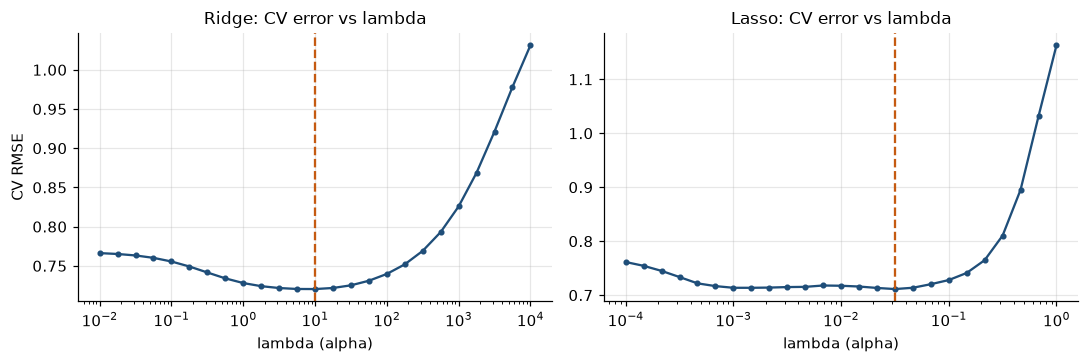

In [8]:
tscv = TimeSeriesSplit(n_splits=5)
alphas_ridge = np.logspace(-2, 4, 25)
alphas_lasso = np.logspace(-4, 0, 25)

def cv_rmse(model):
    return -cross_val_score(model, Xs_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()

ridge_cv = [cv_rmse(Ridge(alpha=a)) for a in alphas_ridge]
lasso_cv = [cv_rmse(Lasso(alpha=a, max_iter=20000)) for a in alphas_lasso]
best_ridge = alphas_ridge[int(np.argmin(ridge_cv))]
best_lasso = alphas_lasso[int(np.argmin(lasso_cv))]
print(f"Best Ridge alpha = {best_ridge:.3g}   CV RMSE = {min(ridge_cv):.3f}")
print(f"Best Lasso alpha = {best_lasso:.3g}   CV RMSE = {min(lasso_cv):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].semilogx(alphas_ridge, ridge_cv, "o-", ms=3, color=COLORS["main"])
axes[0].axvline(best_ridge, color=COLORS["accent"], ls="--")
axes[0].set_title("Ridge: CV error vs lambda"); axes[0].set_xlabel("lambda (alpha)"); axes[0].set_ylabel("CV RMSE")
axes[1].semilogx(alphas_lasso, lasso_cv, "o-", ms=3, color=COLORS["main"])
axes[1].axvline(best_lasso, color=COLORS["accent"], ls="--")
axes[1].set_title("Lasso: CV error vs lambda"); axes[1].set_xlabel("lambda (alpha)")
save(fig, "fig09_regularization_cv")
plt.show()

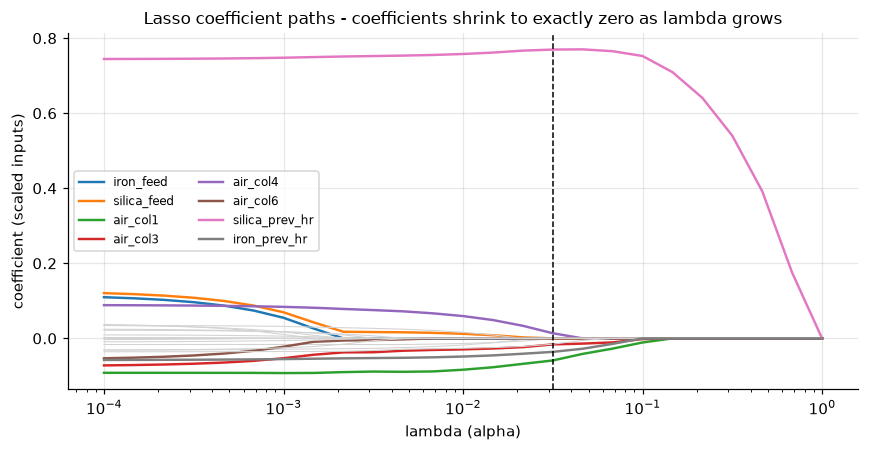

In [9]:
paths = np.array([Lasso(alpha=a, max_iter=20000).fit(Xs_train, y_train).coef_ for a in alphas_lasso])
fig, ax = plt.subplots(figsize=(8, 4.2))
top = np.argsort(-np.abs(paths[0]))[:8]
for j in range(paths.shape[1]):
    if j in top:
        ax.semilogx(alphas_lasso, paths[:, j], lw=1.6, label=data.FEATURES[j])
    else:
        ax.semilogx(alphas_lasso, paths[:, j], lw=0.7, color="lightgrey")
ax.axvline(best_lasso, color="k", ls="--", lw=1)
ax.set_xlabel("lambda (alpha)"); ax.set_ylabel("coefficient (scaled inputs)")
ax.set_title("Lasso coefficient paths - coefficients shrink to exactly zero as lambda grows")
ax.legend(fontsize=8, ncol=2)
save(fig, "fig10_lasso_paths")
plt.show()

In [10]:
ridge = Ridge(alpha=best_ridge).fit(Xs_train, y_train)
lasso = Lasso(alpha=best_lasso, max_iter=20000).fit(Xs_train, y_train)
results["Ridge"] = scores(y_test, ridge.predict(Xs_test))
results["Lasso"] = scores(y_test, lasso.predict(Xs_test))

coef = pd.DataFrame({"MLR": mlr.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=data.FEATURES)
print("Lasso set", (coef["Lasso"] == 0).sum(), "of", len(coef), "coefficients exactly to zero:")
print(list(coef.index[coef["Lasso"] == 0]))
coef.round(3).sort_values("Lasso", key=abs, ascending=False)

Lasso set 16 of 23 coefficients exactly to zero:
['iron_feed', 'silica_feed', 'starch_flow', 'amina_flow', 'pulp_flow', 'pulp_density', 'air_col2', 'air_col5', 'air_col6', 'air_col7', 'level_col1', 'level_col2', 'level_col3', 'level_col4', 'level_col6', 'level_col7']


,MLR,Ridge,Lasso
silica_prev_hr,0.744,0.737,0.770
air_col1,-0.092,-0.089,-0.059
iron_prev_hr,-0.058,-0.063,-0.036
air_col3,-0.074,-0.073,-0.016
level_col5,-0.036,-0.037,-0.015
air_col4,0.089,0.088,0.014
iron_feed,0.116,0.096,-0.000
pulp_density,0.002,0.002,0.000
pulp_pH,-0.016,-0.016,-0.000
pulp_flow,0.000,0.000,0.000


## 6. Random Forest regressor (for comparison)
A non-linear model made of many decision trees. Scaling is not needed for trees.

In [11]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
results["Random Forest"] = scores(y_test, rf.predict(X_test))

## 7. Why we did not shuffle the data
Same Random Forest (sensors only), but with a random 70/30 split instead of a time split:

In [12]:
rf_sensors = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
a, b = train_test_split(hourly, test_size=0.3, random_state=42)
r2_random = r2_score(b[data.TARGET], rf_sensors.fit(a[data.PROCESS_VARS], a[data.TARGET]).predict(b[data.PROCESS_VARS]))
r2_time = r2_score(y_test, rf_sensors.fit(X_train[data.PROCESS_VARS], y_train).predict(X_test[data.PROCESS_VARS]))
print(f"Random Forest, sensors only:  random split R2 = {r2_random:.2f}   vs   time split R2 = {r2_time:.2f}")

Random Forest, sensors only:  random split R2 = 0.33   vs   time split R2 = 0.12


With a random split, the test hours sit between training hours that are almost identical, so the
model looks much better than it really is. The time split is the honest test: it is how the model
would be used in the plant (trained on the past, predicting the future).

## 8. Comparison on the test period

In [13]:
res = pd.DataFrame(results).T
res = res.loc[["Baseline (last hour)", "MLR - sensors only", "MLR - last lab result only",
               "MLR - all 23 inputs", "Ridge", "Lasso", "Random Forest"]]
os.makedirs(data.RES_DIR, exist_ok=True)
res.round(4).to_csv(os.path.join(data.RES_DIR, "regression_results.csv"))
res.round(3)

,R2,RMSE,MAE
Baseline (last hour),0.608,0.711,0.433
MLR - sensors only,-0.126,1.204,0.904
MLR - last lab result only,0.646,0.675,0.461
MLR - all 23 inputs,0.617,0.702,0.490
Ridge,0.619,0.700,0.489
Lasso,0.639,0.681,0.471
Random Forest,0.576,0.739,0.556


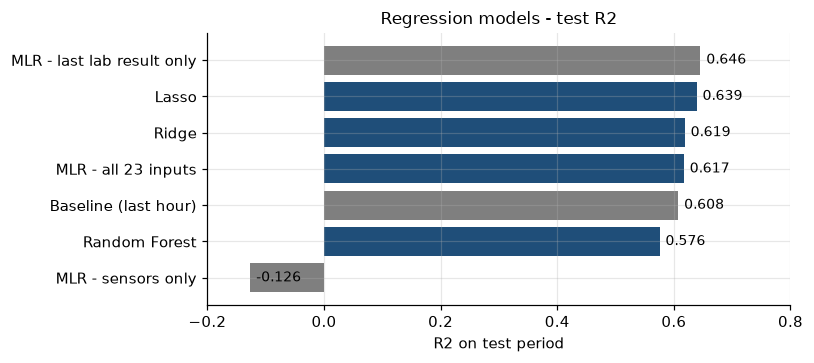

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
order = res.sort_values("R2")
bar_colors = [COLORS["grey"] if ("Baseline" in i or "only" in i) else COLORS["main"] for i in order.index]
ax.barh(order.index, order["R2"].clip(lower=-0.2), color=bar_colors)
for i, v in enumerate(order["R2"]):
    ax.text(max(v, -0.2) + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("R2 on test period"); ax.set_title("Regression models - test R2")
ax.set_xlim(-0.2, 0.8)
save(fig, "fig11_regression_comparison")
plt.show()

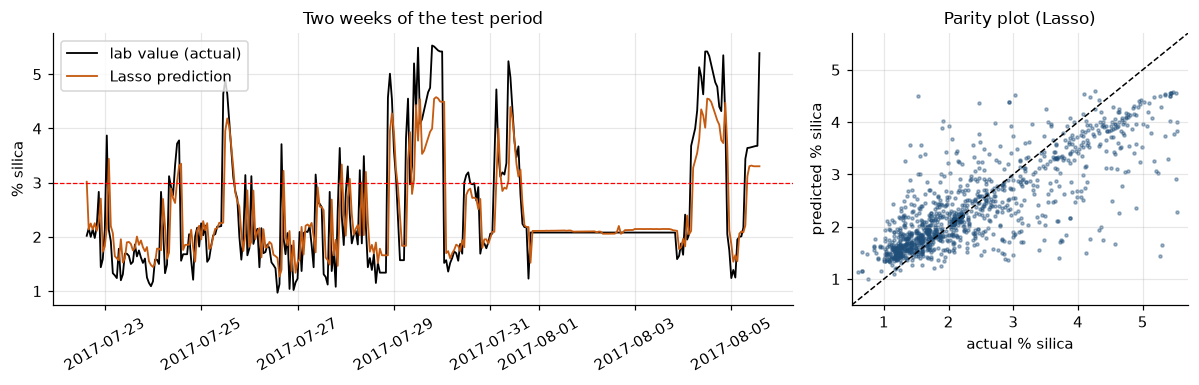

In [15]:
pred_lasso = lasso.predict(Xs_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
window = slice(0, 24 * 14)                                    # first two weeks of the test period
axes[0].plot(test.index[window], y_test.values[window], color="k", lw=1.2, label="lab value (actual)")
axes[0].plot(test.index[window], pred_lasso[window], color=COLORS["accent"], lw=1.2, label="Lasso prediction")
axes[0].axhline(data.OFF_SPEC_LIMIT, color="red", ls="--", lw=0.8)
axes[0].set_ylabel("% silica"); axes[0].set_title("Two weeks of the test period"); axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(y_test, pred_lasso, s=4, alpha=0.4, color=COLORS["main"])
lims = [0.5, 5.7]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_xlim(lims); axes[1].set_ylim(lims)
axes[1].set_xlabel("actual % silica"); axes[1].set_ylabel("predicted % silica"); axes[1].set_title("Parity plot (Lasso)")
save(fig, "fig12_lasso_prediction")
plt.show()

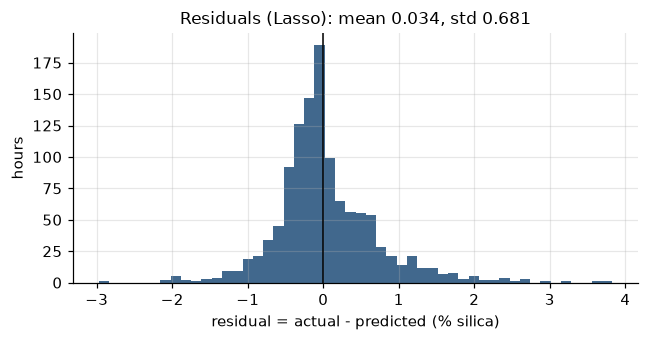

In [16]:
resid = y_test - pred_lasso
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(resid, bins=50, color=COLORS["main"], alpha=0.85)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("residual = actual - predicted (% silica)"); ax.set_ylabel("hours")
ax.set_title(f"Residuals (Lasso): mean {resid.mean():.3f}, std {resid.std():.3f}")
save(fig, "fig13_residuals")
plt.show()

## Conclusions
- Plant sensors alone cannot predict silica in a new time period (test R2 below zero).
  The previous-hour lab result is by far the most useful input.
- With all 23 inputs, plain MLR over-fits slightly. Ridge helps a little and Lasso helps more:
  it sets 16 of the 23 coefficients exactly to zero and keeps only the previous-hour lab values,
  air flow in columns 1, 3 and 4, the level of column 5 and a very small weight on pulp pH. This brings the score
  back to the level of the lab-only model (R2 about 0.64).
- The hourly sensor averages therefore add almost nothing to the *regression* on top of the last lab value.
  This is an honest result on real plant data: silica changes slowly, and the sensors mostly reflect
  operator actions rather than the cause of the change. (In notebook 03 they do help a little for
  detecting off-spec hours.)
- Random Forest is not better than the linear models: with about 2,750 training hours and weak
  sensor signals, the simpler model generalises better to a new time period.
- Our gradient descent reached the same solution as the normal equation when the learning rate was suitable.